# 3. Aprendizaje supervisado

**Pronóstico del consumo eléctrico residencial por distrito con aprendizaje automático** · Sistemas Inteligentes · Grupo 6 · UNMSM

**Objetivo.** Entrenar y comparar once modelos de regresión frente a pronósticos ingenuos, con dos formulaciones del objetivo y dos esquemas de validación, y analizar y exportar el modelo adoptado.

| | |
|---|---|
| **Entradas** | `datos/procesados/panel.parquet` (el grupo de k-means se recalcula con la misma semilla) |
| **Salidas** | `modelos/svr_corrida2.joblib` (pipeline del modelo adoptado, entrenado con todos los distrito-meses) |

### Índice

1. [Configuración](#configuración)
2. [Partición de los datos](#partición-de-los-datos)
3. [Referencias ingenuas y métricas](#referencias-ingenuas-y-métricas)
4. [Regresión lineal: ecuación normal y gradiente descendiente](#regresión-lineal-ecuación-normal-y-gradiente-descendiente)
5. [Entrenamiento de los once modelos](#entrenamiento-de-los-once-modelos)
6. [¿El mejor modelo gana de verdad? Bootstrap por distrito](#el-mejor-modelo-gana-de-verdad-bootstrap-por-distrito)
7. [Análisis del modelo adoptado](#análisis-del-modelo-adoptado)
8. [Modelo final y pronóstico del mes siguiente](#modelo-final-y-pronóstico-del-mes-siguiente)
9. [Verificación con el informe](#verificación-con-el-informe)
10. [Conclusiones](#conclusiones)
11. [Referencias](#referencias)

<a id="configuración"></a>

## 1. Configuración

Importaciones, estilo, panel con los rezagos y el grupo de k-means, y resultados publicados para la verificación final. La búsqueda completa tarda alrededor de un minuto.

In [1]:
import json
import warnings

import estilo
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from estilo import AQUA, BLUE, COLOR_GRUPO, CYAN, EJE_COMA, GRIS, ICE, MESES, MUTED, NAVY, SKY, coma

from ml import config

estilo.aplicar()
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
INFORME = json.loads(config.RESULTADOS.read_text(encoding="utf8"))  # resultados publicados
RESUMEN = json.loads(config.RESUMEN_PREPROCESAMIENTO.read_text(encoding="utf8"))

from ml import caracteristicas as car
from ml import modelos, pronostico
from ml.corridas import CANDIDATOS, comparar_errores, esquemas, preparar
from ml.gradiente import GDRegressor, ecuacion_normal

pn, km = preparar(pd.read_parquet(config.PANEL))
d = car.supervisado(pn)
print(f"Filas supervisadas: {len(d)} ({d['PERIODO'].min()} a {d['PERIODO'].max()})")

Filas supervisadas: 1638 (202502 a 202610)


<a id="partición-de-los-datos"></a>

## 2. Partición de los datos

Se usan dos esquemas:

- **A, aleatorio:** 80 % de entrenamiento y 20 % de prueba (semilla 42). Los hiperparámetros se eligen con validación cruzada de cinco particiones en el entrenamiento (Arlot y Celisse, 2010), procedimiento válido en modelos autorregresivos cuando sus errores no están correlacionados (Bergmeir et al., 2018).
- **B, temporal:** entrenamiento de febrero a diciembre de 2025 y prueba de enero a octubre de 2026, meses que el modelo nunca vio. Es la prueba con la que se adopta el modelo.

In [2]:
E = esquemas(d)
pd.DataFrame({k: {"entrenamiento": len(tr), "prueba": len(te)} for k, (tr, te) in E.items()}).T

,entrenamiento,prueba
A,1310,328
B,858,780


<a id="referencias-ingenuas-y-métricas"></a>

## 3. Referencias ingenuas y métricas

Todo pronóstico se compara con tres referencias que no aprenden (Hyndman y Athanasopoulos, 2021): el **ingenuo** $\hat y_t = y_{t-1}$, el **estacional** $\hat y_t = y_{t-12}$ y el **estacional ajustado** $\hat y_t = y_{t-1}\,y_{t-12}/y_{t-13}$. Las métricas se calculan siempre en kWh (Hyndman y Koehler, 2006):

$$\mathrm{MAE} = \frac{1}{m}\sum_i |\hat y_i - y_i| \qquad \mathrm{RMSE} = \sqrt{\frac{1}{m}\sum_i (\hat y_i - y_i)^2} \qquad R^2 = 1 - \frac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2}$$

El MAE es la métrica principal. El $R^2$ resulta alto incluso para el ingenuo, porque los distritos van de unos 20 a más de 200 kWh.

In [3]:
pd.DataFrame({k: v["test"] for k, v in modelos.ingenuos(E["B"][1]).items()}).T

,MAE,RMSE,R2
Ingenuo (mes anterior),4.2927,6.6106,0.9768
Ingenuo estacional (mismo mes del año anterior),9.0520,11.7151,0.9272
Ingenuo estacional ajustado,3.8922,5.4438,0.9843


<a id="regresión-lineal-ecuación-normal-y-gradiente-descendiente"></a>

## 4. Regresión lineal: ecuación normal y gradiente descendiente

La regresión lineal minimiza $J(\theta) = \frac{1}{m}\lVert X\theta - y \rVert^2$. La **ecuación normal** da la solución exacta $\theta = (X^\top X)^{+} X^\top y$ (pseudoinversa, porque las variables One-Hot son colineales con el intercepto). El **gradiente descendiente**, programado en `ml/gradiente.py`, parte de $\theta = 0$ y actualiza (Bottou et al., 2018):

$$\theta \leftarrow \theta - \alpha \cdot \frac{2}{m} X^\top (X\theta - y)$$

Se prueba con tres tasas de aprendizaje en la corrida 1, esquema B.

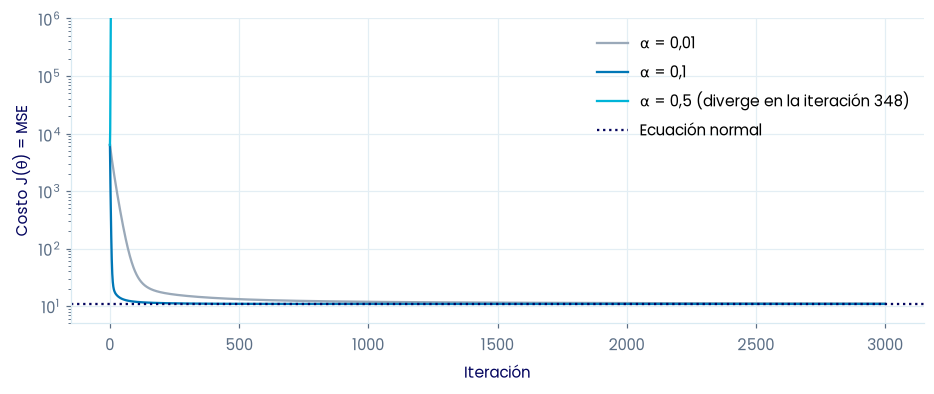

In [4]:
tr, te = E["B"]
pre = modelos.preprocesador(1).fit(tr[car.entradas(1)])
A, t = pre.transform(tr[car.entradas(1)]), tr[car.objetivo(1)].values
mse_ne = float(np.mean((np.c_[np.ones(len(A)), A] @ ecuacion_normal(A, t) - t) ** 2))
fig, ax = plt.subplots()
for lr, col in ((0.01, GRIS), (0.1, BLUE), (0.5, CYAN)):
    gd = GDRegressor(lr=lr, epochs=3000).fit(A, t)
    costo = [
        c for c in gd.costo if c is not None and c < 1e8
    ]  # la curva que diverge se corta fuera del gráfico
    ax.plot(
        costo,
        color=col,
        label=f"α = {coma(lr, 2 if lr < 0.1 else 1)}"
        + (f" (diverge en la iteración {len(gd.costo)})" if gd.diverge else ""),
    )
ax.axhline(mse_ne, color=NAVY, ls=":", label="Ecuación normal")
ax.set(yscale="log", ylim=(5, 1e6), xlabel="Iteración", ylabel="Costo J(θ) = MSE")
ax.legend()
plt.show()

Con α = 0,01 el costo baja lentamente; con **α = 0,1** alcanza el mínimo de la ecuación normal; con α = 0,5 el algoritmo **diverge**. La tasa de aprendizaje es un hiperparámetro decisivo.

<a id="entrenamiento-de-los-once-modelos"></a>

## 5. Entrenamiento de los once modelos

Además de la regresión lineal se entrenan Ridge (Hoerl y Kennard, 1970), Lasso (Tibshirani, 1996), árbol de decisión (Breiman et al., 1984/2017), KNN (Altman, 1992), SVR (Smola y Schölkopf, 2004), red neuronal (Rumelhart et al., 1986), Random Forest (Breiman, 2001), Gradient Boosting (Friedman, 2001) y XGBoost (Chen y Guestrin, 2016). Cada modelo va en un `Pipeline` con el preprocesamiento (estandarización y One-Hot), y sus hiperparámetros se eligen con `GridSearchCV` de cinco particiones minimizando el MAE.

In [5]:
pd.DataFrame(
    [
        {
            "modelo": k,
            "hiperparámetros": ", ".join(
                f"{modelos.nombre_parametro(p)}: {v}" for p, v in rej.items()
            ),
            "combinaciones": int(np.prod([len(v) for v in rej.values()])),
        }
        for k, (_, rej) in modelos.REJILLAS.items()
    ]
).set_index("modelo")

,hiperparámetros,combinaciones
modelo,,
Ridge,"alpha: [0.01, 0.1, 1, 10, 100]",5
Lasso,"alpha: [0.0001, 0.001, 0.01, 0.1, 1, 10]",6
Árbol de decisión,"max_depth: [3, 5, 10, None], min_samples_leaf:...",12
KNN,"n_neighbors: [3, 5, 10, 20, 40], weights: ['un...",10
SVR,"C: [0.1, 1, 10, 100], epsilon: [0.01, 0.1, 0.5]",12
Red neuronal (MLP),"hidden_layer_sizes: [(32,), (64, 32)], alpha: ...",6
Random Forest,"n_estimators: [200, 500], max_depth: [None, 10...",18
Gradient Boosting,"n_estimators: [200, 500], learning_rate: [0.03...",12
XGBoost,"n_estimators: [200, 500], learning_rate: [0.03...",16


In [6]:
res = {}
for f in (1, 2):
    for s, (tr, te) in E.items():
        res[(f, s)] = modelos.evaluar(f, tr, te)


def tabla(f, s):
    t = {
        **{k: v["test"] for k, v in modelos.ingenuos(E[s][1]).items()},
        **{k: v["test"] for k, v in res[(f, s)].items() if not k.startswith("_")},
    }
    return pd.DataFrame(t).T.sort_values("MAE")


print("Corrida 1 (nivel), esquema B: prueba temporal 2026")
display(tabla(1, "B").round(3))

Corrida 1 (nivel), esquema B: prueba temporal 2026


,MAE,RMSE,R2
Ingenuo estacional ajustado,3.8920,5.4440,0.9840
Ingenuo (mes anterior),4.2930,6.6110,0.9770
Red neuronal (MLP),4.7270,6.5130,0.9770
SVR,5.2460,7.9190,0.9670
Ridge,5.5390,7.2460,0.9720
Lasso,5.5680,7.2760,0.9720
Gradient Boosting,5.6930,7.8610,0.9670
Regresión lineal (gradiente descendiente),5.7720,7.5510,0.9700
Regresión lineal (ecuación normal),5.7730,7.5520,0.9700
XGBoost,5.9110,8.2370,0.9640


Al pronosticar el **nivel**, en la prueba temporal **ningún modelo supera al ingenuo** (4,29 kWh), aunque los $R^2$ superen 0,93: el consumo de 2026 subió y los modelos entrenados con 2025 lo subestiman. Un $R^2$ alto no basta para validar un pronóstico.

In [7]:
print("Corrida 2 (variación mensual), esquema B: prueba temporal 2026")
display(tabla(2, "B").round(3))

Corrida 2 (variación mensual), esquema B: prueba temporal 2026


,MAE,RMSE,R2
SVR,3.1550,5.2150,0.9860
Random Forest,3.1930,5.1960,0.9860
KNN,3.2050,5.2170,0.9860
XGBoost,3.2650,5.3660,0.9850
Lasso,3.4320,5.3620,0.9850
Gradient Boosting,3.4450,5.6600,0.9830
Ridge,3.5550,5.5280,0.9840
Regresión lineal (gradiente descendiente),3.6430,5.5960,0.9830
Regresión lineal (ecuación normal),3.6430,5.5960,0.9830
Red neuronal (MLP),3.6910,5.7400,0.9830


Al pronosticar la **variación**, los once modelos superan al ingenuo. **SVR** obtiene el menor MAE, seguido de cerca por Random Forest, KNN y XGBoost.

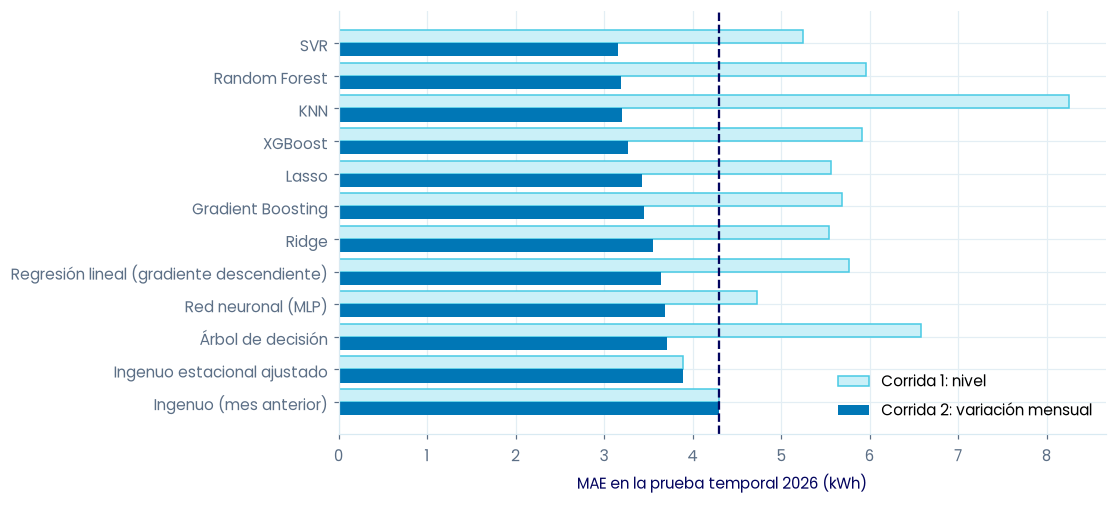

In [8]:
c1, c2 = tabla(1, "B")["MAE"], tabla(2, "B")["MAE"]
orden = (
    c2.drop(
        ["Ingenuo estacional (mismo mes del año anterior)", "Regresión lineal (ecuación normal)"]
    )
    .sort_values(ascending=False)
    .index
)
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(orden))
ax.barh(y + 0.2, c1[orden], 0.4, color=ICE, edgecolor=AQUA, label="Corrida 1: nivel")
ax.barh(y - 0.2, c2[orden], 0.4, color=BLUE, label="Corrida 2: variación mensual")
ax.axvline(c2["Ingenuo (mes anterior)"], color=NAVY, ls="--")
ax.set_yticks(y, orden)
ax.set_xlabel("MAE en la prueba temporal 2026 (kWh)")
ax.legend(loc="lower right")
plt.show()

<a id="el-mejor-modelo-gana-de-verdad-bootstrap-por-distrito"></a>

## 6. ¿El mejor modelo gana de verdad? Bootstrap por distrito

Como se adopta el modelo de menor MAE, se estima si su ventaja puede deberse al azar con un bootstrap (Efron y Tibshirani, 1994): se remuestrean 2000 veces los 78 distritos con sus diez meses de 2026 y se calcula la diferencia de MAE frente a cada modelo. Si el intervalo del 95 % incluye el cero, los modelos empatan.

In [9]:
tr, te = E["B"]
rb = res[(2, "B")]
mejor = min(CANDIDATOS, key=lambda k: rb[k]["test"]["MAE"])
err = {k: np.abs(rb[k]["_pred"] - te["y"].values) for k in CANDIDATOS}
err["Ingenuo (mes anterior)"] = np.abs(te["lag1"].values - te["y"].values)
comp = pd.DataFrame(comparar_errores(err, mejor, te["UBIGEO"].values)).T.sort_values("diferencia")
comp["conclusión"] = np.where(
    (comp["ic_inferior"] < 0) & (comp["ic_superior"] > 0), "Empate", f"{mejor} mejor"
)
print("Modelo adoptado:", mejor)
comp.round(3)

Modelo adoptado: SVR


,diferencia,ic_inferior,ic_superior,p_menor,conclusión
Ingenuo (mes anterior),-1.1380,-1.4680,-0.7890,1.0000,SVR mejor
Árbol de decisión,-0.5540,-0.7160,-0.3880,1.0000,SVR mejor
Red neuronal (MLP),-0.5360,-0.6700,-0.4090,1.0000,SVR mejor
Ridge,-0.4000,-0.5500,-0.2510,1.0000,SVR mejor
Gradient Boosting,-0.2910,-0.4780,-0.1210,1.0000,SVR mejor
Lasso,-0.2780,-0.4390,-0.1140,1.0000,SVR mejor
XGBoost,-0.1100,-0.2780,0.0370,0.9260,Empate
KNN,-0.0500,-0.1520,0.0600,0.8310,Empate
Random Forest,-0.0380,-0.1690,0.0950,0.7000,Empate


SVR es significativamente mejor que el ingenuo y que cinco modelos, pero **empata** con Random Forest, KNN y XGBoost: con diez meses de prueba, cualquiera de los cuatro daría un pronóstico de calidad equivalente. Se adoptó SVR por el criterio fijado de antemano, el menor MAE.

<a id="análisis-del-modelo-adoptado"></a>

## 7. Análisis del modelo adoptado

Se analiza el SVR en la prueba temporal: real frente a pronosticado, error por grupo de distritos y por mes, e importancia de las variables por permutación (aumento del MAE al desordenar cada variable; Breiman, 2001).

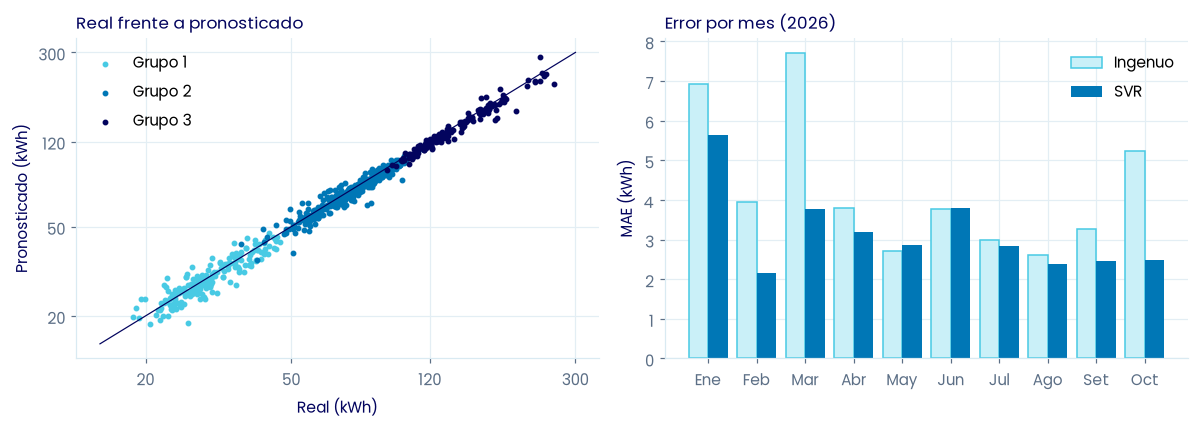

,MAE ingenuo,MAE SVR
grupo,,
1,2.0700,2.1300
2,3.8800,2.7000
3,7.5800,5.2700


In [10]:
p = rb[mejor]["_pred"]
t2 = te.assign(pred=p, err=np.abs(p - te["y"]), err_ing=np.abs(te["lag1"] - te["y"]))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
for g in (1, 2, 3):
    q = t2[t2["grupo"] == g]
    a1.scatter(q["y"], q["pred"], s=8, color=COLOR_GRUPO[g], label=f"Grupo {g}")
a1.plot([15, 300], [15, 300], color=NAVY, lw=0.8)
a1.set(
    xscale="log",
    yscale="log",
    xlabel="Real (kWh)",
    ylabel="Pronosticado (kWh)",
    title="Real frente a pronosticado",
)
a1.legend()
for eje in (a1.xaxis, a1.yaxis):
    eje.set_major_locator(plt.FixedLocator([20, 50, 120, 300]))
    eje.set_major_formatter(EJE_COMA)
    eje.set_minor_locator(plt.NullLocator())
mes = t2.groupby("PERIODO")[["err_ing", "err"]].mean()
x = np.arange(len(mes))
a2.bar(x - 0.2, mes["err_ing"], 0.4, color=ICE, edgecolor=AQUA, label="Ingenuo")
a2.bar(x + 0.2, mes["err"], 0.4, color=BLUE, label=mejor)
a2.set_xticks(x, [MESES[int(m[4:]) - 1] for m in mes.index])
a2.set(ylabel="MAE (kWh)", title="Error por mes (2026)")
a2.legend()
plt.tight_layout()
plt.show()
t2.groupby("grupo")[["err_ing", "err"]].mean().rename(
    columns={"err_ing": "MAE ingenuo", "err": f"MAE {mejor}"}
).round(2)

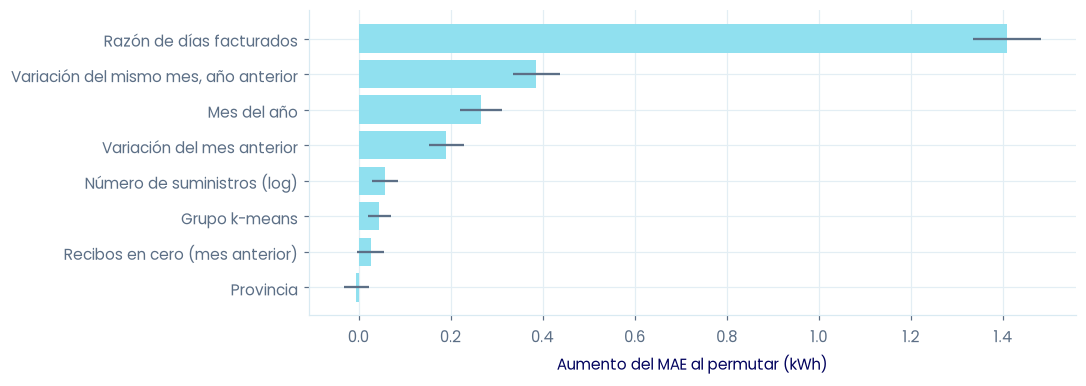

In [11]:
NOMBRES = {
    "dias_ratio": "Razón de días facturados",
    "dl_seas": "Variación del mismo mes, año anterior",
    "dl_prev": "Variación del mes anterior",
    "mes": "Mes del año",
    "p_cero_lag1": "Recibos en cero (mes anterior)",
    "grupo": "Grupo k-means",
    "log_n": "Número de suministros (log)",
    "PROV_N": "Provincia",
}
imp = (
    pd.DataFrame(modelos.importancia_permutacion(rb[mejor]["_model"], 2, te))
    .set_index("variable")
    .rename(index=NOMBRES)
)
fig, ax = plt.subplots(figsize=(9, 3.6))
imp = imp.iloc[::-1]
ax.barh(imp.index, imp["media"], xerr=imp["sd"], color=SKY, ecolor=MUTED)
ax.set_xlabel("Aumento del MAE al permutar (kWh)")
plt.show()

El modelo mejora al ingenuo sobre todo en los grupos 2 y 3; en el grupo 1, de consumo bajo, empata con él. La variable más influyente es la **razón de días facturados**: parte de la variación del recibo se debe a que el periodo facturado tiene más o menos días, no a cambios de hábito.

<a id="modelo-final-y-pronóstico-del-mes-siguiente"></a>

## 8. Modelo final y pronóstico del mes siguiente

Para pronosticar el mes posterior al último publicado (noviembre de 2026), el SVR se reentrena con **todos** los distrito-meses supervisados y se exporta. Dos entradas de ese mes aún no se conocen: los días facturados y el número de suministros se suponen iguales a los del último mes.

In [12]:
import joblib

params = rb[mejor]["params"]
final = pronostico.entrenar(d, params, nombre=mejor)
destino = config.RAIZ / "modelos" / "svr_corrida2.joblib"
destino.parent.mkdir(exist_ok=True)
joblib.dump(
    {"modelo": final, "nombre": mejor, "params": params, "entradas": car.entradas(2)}, destino
)
print("Guardado:", destino.relative_to(config.RAIZ), "·", mejor, params)
sig = pd.DataFrame(
    [x.__dict__ for x in pronostico.pronosticar(final, pronostico.filas_siguiente(pn))]
)
sig = sig.merge(
    pn.drop_duplicates("UBIGEO")[["UBIGEO", "DIST_N"]], left_on="ubigeo", right_on="UBIGEO"
)
sig.sort_values("variacion", ascending=False)[
    ["DIST_N", "periodo", "ultimo_consumo", "consumo", "variacion"]
].head(5)

Guardado: modelos\svr_corrida2.joblib · SVR {'C': 1, 'epsilon': 0.1}


,DIST_N,periodo,ultimo_consumo,consumo,variacion
30,CHALACO,202611,25.7872,29.3593,0.1385
18,SICCHEZ,202611,32.0234,36.4475,0.1382
7,LAS LOMAS,202611,74.7215,81.0040,0.0841
14,MONTERO,202611,37.7125,40.7674,0.0810
10,AYABACA,202611,34.2132,36.6277,0.0706


<a id="verificación-con-el-informe"></a>

## 9. Verificación con el informe

In [13]:
for f in (1, 2):
    for s in ("A", "B"):
        for k, v in res[(f, s)].items():
            if not k.startswith("_"):
                assert abs(v["test"]["MAE"] - INFORME[f"c{f}{s}"][k]["test"]["MAE"]) < 1e-9, (
                    f,
                    s,
                    k,
                )
assert mejor == INFORME["mejor"]
print("Las métricas de los cuatro escenarios y el modelo adoptado coinciden con el informe.")

Las métricas de los cuatro escenarios y el modelo adoptado coinciden con el informe.


<a id="conclusiones"></a>

## 10. Conclusiones

- La **formulación del objetivo** fue decisiva: pronosticando el nivel, ningún modelo supera al ingenuo en 2026; pronosticando la variación mensual, los once lo superan.
- **SVR** (núcleo RBF, C = 1, ε = 0,1) obtiene un MAE de **3,15 kWh**, 26,5 % menos que el ingenuo, aunque empata estadísticamente con Random Forest, KNN y XGBoost.
- El gradiente descendiente programado alcanza la solución de la ecuación normal con α = 0,1 y diverge con α = 0,5.
- El modelo final se exporta a `modelos/svr_corrida2.joblib`; la API lo reentrena al arrancar con los mismos hiperparámetros.

<a id="referencias"></a>

## 11. Referencias

- Altman, N. S. (1992). An introduction to kernel and nearest-neighbor nonparametric regression. *The American Statistician, 46*(3), 175–185. https://doi.org/10.1080/00031305.1992.10475879
- Arlot, S. y Celisse, A. (2010). A survey of cross-validation procedures for model selection. *Statistics Surveys, 4*, 40–79. https://doi.org/10.1214/09-SS054
- Bergmeir, C., Hyndman, R. J. y Koo, B. (2018). A note on the validity of cross-validation for evaluating autoregressive time series prediction. *Computational Statistics & Data Analysis, 120*, 70–83. https://doi.org/10.1016/j.csda.2017.11.003
- Bottou, L., Curtis, F. E. y Nocedal, J. (2018). Optimization methods for large-scale machine learning. *SIAM Review, 60*(2), 223–311. https://doi.org/10.1137/16M1080173
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324
- Breiman, L., Friedman, J. H., Olshen, R. A. y Stone, C. J. (2017). *Classification and regression trees*. Routledge. https://doi.org/10.1201/9781315139470 (Trabajo original publicado en 1984)
- Chen, T. y Guestrin, C. (2016). XGBoost: A scalable tree boosting system. En *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 785–794). ACM. https://doi.org/10.1145/2939672.2939785
- Efron, B. y Tibshirani, R. J. (1994). *An introduction to the bootstrap*. Chapman and Hall/CRC. https://doi.org/10.1201/9780429246593
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. https://doi.org/10.1214/aos/1013203451
- Hoerl, A. E. y Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. *Technometrics, 12*(1), 55–67. https://doi.org/10.1080/00401706.1970.10488634
- Hyndman, R. J. y Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3.ª ed.). OTexts. https://otexts.com/fpp3/
- Hyndman, R. J. y Koehler, A. B. (2006). Another look at measures of forecast accuracy. *International Journal of Forecasting, 22*(4), 679–688. https://doi.org/10.1016/j.ijforecast.2006.03.001
- Rumelhart, D. E., Hinton, G. E. y Williams, R. J. (1986). Learning representations by back-propagating errors. *Nature, 323*(6088), 533–536. https://doi.org/10.1038/323533a0
- Smola, A. J. y Schölkopf, B. (2004). A tutorial on support vector regression. *Statistics and Computing, 14*(3), 199–222. https://doi.org/10.1023/B:STCO.0000035301.49549.88
- Tibshirani, R. (1996). Regression shrinkage and selection via the lasso. *Journal of the Royal Statistical Society: Series B (Methodological), 58*(1), 267–288. https://doi.org/10.1111/j.2517-6161.1996.tb02080.x